# SmishGuard: baseline versus proposed Multinomial Naive Bayes

Execute top to bottom in Python 3.12 (Google Colab or the local research environment).
The complete implementation is embedded below; no repository checkout is needed in Colab.
Only the configuration cell needs changing for another input/output location.

This is **retrospective research**: the October 12 corpus has already influenced
earlier models. A new split cannot create independent prospective evidence.
Source/rule labels are inherited, not independently verified. Keep all message-bearing
files and fitted vocabulary private. The notebook displays aggregate results only.
Production assets and existing notebooks are preserved.

Before fitting, the fixed selection rule is maximum validation scam F1, then recall,
precision, smaller classifier file, configuration ID. No threshold tuning, resampling,
feature selection from held-out data, or refitting on validation. Default NB threshold
is >=0.5; SVM margin threshold is >=0. No claim of calibrated fraud probability.


## 1. Environment and configuration

The default Drive ZIP is `/content/drive/MyDrive/datasets/smishguard_dataset_2026-10-12.zip`.
Drive mounts only in Colab when needed. Set `SMISHGUARD_NB_DATASET` and
`SMISHGUARD_NB_OUTPUT` to configure paths without changing intermediate cells.
Each execution requires a **new** output directory; completed evidence is never overwritten.
Google Colab execution itself has not been tested by running in a remote Colab account;
the same notebook is executed locally with the pinned packages.


In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
PINS = ['numpy==2.2.6','scipy==1.15.3','scikit-learn==1.6.1','pandas==2.3.3',
        'matplotlib==3.10.7','joblib==1.6.0','threadpoolctl==3.7.0']
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *PINS])
from datetime import datetime, timezone
STAMP = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
if IN_COLAB:
    default_zip = Path('/content/drive/MyDrive/datasets/smishguard_dataset_2026-10-12.zip')
    default_output = Path('/content/drive/MyDrive/smishguard-results') / ('nb-comparison-' + STAMP)
else:
    root = Path.cwd() if (Path.cwd()/'research').is_dir() else Path.cwd().parent
    default_zip = root/'research/data/newdata-20261013/smishguard_dataset_2026-10-12.zip'
    default_output = root/'research/runs/nb-comparison-20261016'/STAMP
DATASET_PATH = Path(os.environ.get('SMISHGUARD_NB_DATASET', str(default_zip))).expanduser().resolve()
OUTPUT_PATH = Path(os.environ.get('SMISHGUARD_NB_OUTPUT', str(default_output))).expanduser().resolve()
ZIP_MEMBER = os.environ.get('SMISHGUARD_NB_MEMBER', 'smishguard_dataset_2026-10-12/smishguard_dataset.csv')
if IN_COLAB and ('/content/drive/' in str(DATASET_PATH) or '/content/drive/' in str(OUTPUT_PATH)):
    from google.colab import drive
    drive.mount('/content/drive')
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f'Dataset ZIP missing: {DATASET_PATH}. Configure SMISHGUARD_NB_DATASET or DATASET_PATH.')
print('Python:', sys.version)
print('Dataset:', DATASET_PATH.name, '| Output:', OUTPUT_PATH)


Python: 3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]
Dataset: smishguard_dataset_2026-10-12.zip | Output: C:\Users\Jassim Trinidad\OneDrive\Desktop\smishguard\research\runs\nb-comparison-20261016\notebook-run-v3


## 2. Complete audited implementation

The CSV schema is inspected explicitly. Only `smishguard_dataset.csv` is extracted
into memory; `asea_ready.csv` is an overlapping auxiliary copy and the ZIP's scripts
are never run. The third label `gambling_ad` is held, with no invented binary mapping.
Flagged records and normalized label conflicts are held. Exact/casefold/whitespace
duplicates are removed **before** splitting, retaining first eligible occurrence.

The existing three-source research scope is retained. Pending GitHub and team
permission/consent rows remain held. The source ledger and inherited labels stay
private; this is not a source-license or label-quality certification.

Text normalization collapses whitespace only, followed by Unicode lowercase.
The shared tokenizer preserves whole HTTP(S)/www URLs (including attached terminal
punctuation), currency amounts, decimal/grouped numbers and one-character words.
No URL/amount masking, translation, stemming or accent removal is added.
Both approaches remove the same conservative fixed English list, avoiding the full
English list's Filipino collisions such as `at`, `may`, `an`, and retaining negations.
No automatic language detection or Tagalog stopword removal is used.

All models use TF-IDF (1,2), raw TF, smoothed IDF, L2 normalization, min_df=1 and
max_features=None. A: NB alpha=1.0; B: NB alpha=0.1. Additional NB alpha=.01/.5/2
and LinearSVC C=1 use the same features. This isolates alpha for the NB comparison.


In [2]:
import importlib.util, tempfile
IMPLEMENTATION_SOURCE = '"""Standalone, retrospective NB comparison. Never writes Android production assets.\n\nThis module is embedded verbatim in the Colab notebook. Message-bearing data,\nvocabulary, predictions and models stay in a new private run directory.\n"""\nfrom collections import Counter, defaultdict\nfrom difflib import SequenceMatcher\nfrom pathlib import Path\nimport argparse\nimport csv\nimport hashlib\nimport importlib.metadata\nimport io\nimport json\nimport math\nimport pickle\nimport platform\nimport re\nimport stat\nimport sys\nimport time\nimport unicodedata\nimport zipfile\n\nimport numpy as np\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score\nfrom sklearn.model_selection import StratifiedGroupKFold\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.svm import LinearSVC\nfrom threadpoolctl import threadpool_limits\n\nSEED = 42\nMEMBER = \'smishguard_dataset_2026-10-12/smishguard_dataset.csv\'\nSOURCES = (\'Kaggle: Tagalog-SMS (ZERO, 2025)\',\n           \'Kaggle: PH Spam + Marketing SMS (Chua, 2022)\',\n           \'Kaggle: Philippine Spam/Scam SMS (bwandowando)\')\n# Fixed before fitting: conservative English-only removal, shared by A and B.\n# Avoid the full English list, which contains Filipino/Taglish words at/may/an,\n# and preserve negations and security-warning words. No language detection.\nSTOP_WORDS = sorted(\'the these those which whom whose with from yours their theirs yourself yourselves\'.split())\nTOKEN_PATTERN = r\'(?u)https?://[^\\s<>]+|www\\.[^\\s<>]+|[₱$€£]\\s?\\d+(?:[,.]\\d+)*|\\b\\d+(?:[,.]\\d+)*\\b|\\b\\w+\\b\'\nURL = re.compile(r\'https?://[^\\s<>]+|www\\.[^\\s<>]+\', re.I)\nPOLICY = dict(primary=\'validation scam F1\', tie_breaks=[\'scam recall\', \'scam precision\', \'smaller model bytes\', \'configuration ID\'],\n              threshold=\'NB posterior >=0.5; SVM margin >=0; no threshold tuning\',\n              refit=\'training only; validation never refitted\', deployment_approved=False)\n\n\ndef save(path, value):\n    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding=\'utf-8\')\n\n\ndef load(path):\n    return json.loads(Path(path).read_text(encoding=\'utf-8\'))\n\n\ndef digest(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef normalize(text):\n    """Only collapse whitespace. No URL/amount masking, stemming or translation."""\n    if not isinstance(text, str):\n        raise ValueError(\'Text must be a string\')\n    return re.sub(r\'\\s+\', \' \', text).strip()\n\n\ndef read_dataset(path, member=MEMBER):\n    path = Path(path)\n    if path.suffix.lower() != \'.zip\':\n        raise ValueError(\'Use the original dataset ZIP to retain its identity/schema\')\n    with zipfile.ZipFile(path) as z:\n        if sum(e.file_size for e in z.infolist()) > 100_000_000:\n            raise ValueError(\'ZIP exceeds 100 MB uncompressed limit\')\n        for e in z.infolist():\n            parts = e.filename.replace(\'\\\\\', \'/\').split(\'/\')\n            if e.filename.startswith((\'/\', \'\\\\\')) or \'..\' in parts or \':\' in e.filename or stat.S_ISLNK(e.external_attr >> 16):\n                raise ValueError(\'Unsafe ZIP member\')\n        # Extract only the known CSV, into memory; never execute bundled scripts.\n        raw = z.read(member)\n    reader = csv.DictReader(io.StringIO(raw.decode(\'utf-8-sig\'), newline=\'\'), strict=True)\n    required = {\'id\', \'text\', \'label\', \'category\', \'language\', \'source\', \'source_category\',\n                \'sender\', \'date\', \'template_group\', \'label_method\', \'confidence\', \'needs_review\'}\n    if not reader.fieldnames or set(reader.fieldnames) != required or len(reader.fieldnames) != len(required):\n        raise ValueError(\'Unexpected October 12 CSV schema\')\n    rows = list(reader)\n    if not rows or any(None in r or any(v is None for v in r.values()) for r in rows):\n        raise ValueError(\'Empty or malformed dataset CSV\')\n    return rows, dict(zip_sha256=digest(path), member=member,\n        csv_sha256=hashlib.sha256(raw).hexdigest(), bytes=len(raw), schema=reader.fieldnames,\n        extraction=\'Known CSV read into memory; other ZIP files never executed\')\n\n\ndef counts(rows):\n    c = Counter(r[\'label\'] for r in rows)\n    return dict(records=len(rows), ham=c[0], smishing=c[1], scam_fraction=c[1]/len(rows) if rows else None)\n\n\ndef clean(rows):\n    if len({r[\'id\'] for r in rows}) != len(rows) or any(not r[\'id\'] for r in rows):\n        raise ValueError(\'Missing/duplicate record IDs\')\n    buckets = defaultdict(list)\n    for i, r in enumerate(rows):\n        buckets[normalize(r[\'text\']).casefold()].append(i)\n    # Examine all labels, including unsupported/flagged/source-held records.\n    conflicts = {k for k, ii in buckets.items() if len({rows[i][\'label\'] for i in ii}) > 1}\n    retained, ledger, seen = [], [], set()\n    mapping = {\'ham\': 0, \'smishing\': 1}\n    for r in rows:\n        text = normalize(r[\'text\']); key = text.casefold(); reasons = []\n        if r[\'label\'] not in mapping:\n            reasons.append(\'unsupported_label_\' + r[\'label\'])\n        if r[\'source\'] not in SOURCES:\n            reasons.append(\'existing_source_scope_hold\')\n        if r[\'needs_review\'].lower() not in (\'true\', \'false\'):\n            raise ValueError(\'Unknown needs_review status\')\n        if r[\'needs_review\'].lower() == \'true\':\n            reasons.append(\'flagged_for_label_review\')\n        if not text or \'\\x00\' in text or \'\\ufffd\' in text or len(text) > 10000:\n            reasons.append(\'empty_malformed_or_overlong\')\n        if key in conflicts:\n            reasons.append(\'conflicting_normalized_labels\')\n        if not reasons:\n            if key in seen:\n                reasons.append(\'duplicate_normalized_text\')\n            else:\n                seen.add(key)\n                retained.append(dict(r, text=text, label=mapping[r[\'label\']], original_label=r[\'label\']))\n        ledger.append(dict(id=r[\'id\'], reasons=reasons, text_changed=text != r[\'text\'],\n                           original_label=r[\'label\'], key_sha256=hashlib.sha256(key.encode()).hexdigest()))\n    audit = dict(input_records=len(rows), input_labels=dict(Counter(r[\'label\'] for r in rows)),\n        raw_exact_duplicate_extra_rows=len(rows)-len({r[\'text\'] for r in rows}),\n        normalized_duplicate_extra_rows=len(rows)-len(buckets),\n        conflicting_normalized_groups=len(conflicts),\n        conflicting_record_ids=[rows[i][\'id\'] for k in conflicts for i in buckets[k]],\n        missing={k:sum(not r[k].strip() for r in rows) for k in rows[0]},\n        exclusion_reason_counts=dict(Counter(reason for e in ledger for reason in e[\'reasons\'])),\n        excluded_records=sum(bool(e[\'reasons\']) for e in ledger), after_cleaning=counts(retained),\n        language_before=dict(Counter(r[\'language\'] for r in rows)),\n        language_after=dict(Counter(r[\'language\'] for r in retained)),\n        sources_after=dict(Counter(r[\'source\'] for r in retained)),\n        label_status=\'Inherited source/rule labels, not independently verified\',\n        source_policy=\'Existing three-source research scope; GitHub permission and team consent/use remain unresolved\',\n        text_policy=\'Dataset CSV text, whitespace collapsed only; URLs/numbers/currency preserved; no further redaction\')\n    return retained, ledger, audit\n\n\ndef template_key(text):\n    value = URL.sub(\' \', text.casefold())\n    value = re.sub(r\'\\d+\', \' \', value)\n    # Unicode word characters, avoiding the previous ASCII-only grouping gap.\n    return re.sub(r\'\\s+\', \' \', re.sub(r\'[^\\w\\s]|_\', \' \', value)).strip()\n\n\ndef group_rows(rows):\n    texts = [template_key(r[\'text\']) for r in rows]\n    hist = [Counter(t) for t in texts]; parent = list(range(len(rows)))\n    def root(i):\n        while parent[i] != i:\n            parent[i] = parent[parent[i]]; i = parent[i]\n        return i\n    def join(i, j):\n        parent[root(i)] = root(j)\n    for field in (\'template_group\', \'sender\', \'campaign\', \'conversation\'):\n        seen = {}\n        for i, r in enumerate(rows):\n            v = r.get(field, \'\')\n            if v and v.lower() not in (\'unknown\', \'nan\', \'none\'):\n                key = v if field == \'template_group\' else (r[\'source\'], v)\n                if key in seen:\n                    join(i, seen[key])\n                seen[key] = i\n    for i in range(len(rows)):\n        for j in range(i):\n            if root(i) == root(j):\n                continue\n            if texts[i] == texts[j]:\n                join(i, j); continue\n            total = max(1, len(texts[i])+len(texts[j]))\n            if 2*min(len(texts[i]), len(texts[j]))/total < .85:\n                continue\n            if 2*sum(min(v, hist[j].get(k, 0)) for k, v in hist[i].items())/total < .85:\n                continue\n            if SequenceMatcher(None, texts[i], texts[j], autojunk=False).ratio() >= .85:\n                join(i, j)\n    return np.array([root(i) for i in range(len(rows))])\n\n\ndef validate_split(rows, groups, split):\n    flat = [i for ids in split.values() for i in ids]\n    if len(flat) != len(rows) or set(flat) != set(range(len(rows))):\n        raise ValueError(\'Splits must be a disjoint complete cover\')\n    for p, ids in split.items():\n        if {rows[i][\'label\'] for i in ids} != {0, 1}:\n            raise ValueError(p + \' lacks both classes; do not search favorable seeds\')\n        for q, jj in split.items():\n            if p < q and (set(groups[ids]) & set(groups[jj]) or\n                {rows[i][\'text\'].casefold() for i in ids} & {rows[j][\'text\'].casefold() for j in jj}):\n                raise ValueError(\'Group or text leakage between splits\')\n\n\ndef split_rows(rows, groups):\n    y = np.array([r[\'label\'] for r in rows])\n    if any(len(set(groups[y == c])) < 20 for c in (0, 1)):\n        raise ValueError(\'Need >=20 groups per class for this prespecified split\')\n    folds = [b for _, b in StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED).split(y, y, groups)]\n    split = {p:np.concatenate(folds[a:b]).tolist() for p, a, b in\n             [(\'train\', 0, 14), (\'validation\', 14, 17), (\'test\', 17, 20)]}\n    validate_split(rows, groups, split)\n    return split\n\n\ndef vectorizer():\n    return TfidfVectorizer(lowercase=True, strip_accents=None, token_pattern=TOKEN_PATTERN,\n        stop_words=STOP_WORDS, ngram_range=(1, 2), max_features=None, min_df=1,\n        max_df=1.0, norm=\'l2\', use_idf=True, smooth_idf=True, sublinear_tf=False)\n\n\ndef metrics(y, pred):\n    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()\n    report = classification_report(y, pred, labels=[0, 1], target_names=[\'ham\', \'smishing\'],\n                                   output_dict=True, zero_division=0)\n    return dict(accuracy=float(accuracy_score(y, pred)), precision=report[\'smishing\'][\'precision\'],\n        recall=report[\'smishing\'][\'recall\'], f1=report[\'smishing\'][\'f1-score\'],\n        macro_f1=float(f1_score(y, pred, average=\'macro\', zero_division=0)),\n        fpr=float(fp/(tn+fp)), fnr=float(fn/(fn+tp)),\n        confusion_matrix=[[int(tn), int(fp)], [int(fn), int(tp)]], classification_report=report)\n\n\ndef matrix():\n    return [dict(id=\'A-baseline\', algorithm=\'nb\', alpha=1.0),\n            dict(id=\'B-proposed\', algorithm=\'nb\', alpha=.1),\n            *[dict(id=\'NB-alpha-\'+str(a), algorithm=\'nb\', alpha=a) for a in (.01, .5, 2.0)],\n            dict(id=\'SVM-reference\', algorithm=\'svm\', C=1.0)]\n\n\ndef predictions(model, x, spec):\n    # Use explicit >= for ties consistently in export and inference.\n    if spec[\'algorithm\'] == \'nb\':\n        score = model.predict_proba(x)[:, 1]; threshold = .5\n    else:\n        score = model.decision_function(x); threshold = 0.\n    return np.asarray(score), (score >= threshold).astype(int)\n\n\ndef choose(results):\n    return sorted(results, key=lambda r:(-r[\'validation\'][\'f1\'], -r[\'validation\'][\'recall\'],\n        -r[\'validation\'][\'precision\'], r[\'model_bytes\'], r[\'spec\'][\'id\']))[0][\'spec\'][\'id\']\n\n\ndef train(dataset, output, member=MEMBER):\n    output = Path(output); output.mkdir(parents=True, exist_ok=False)\n    rows, identity = read_dataset(dataset, member)\n    clean_rows, ledger, audit = clean(rows)\n    save(output/\'cleaning-ledger.json\', ledger); save(output/\'dataset.json\', clean_rows)\n    start = time.perf_counter(); groups = group_rows(clean_rows)\n    split = split_rows(clean_rows, groups)\n    audit[\'grouping_seconds\'] = time.perf_counter()-start\n    audit[\'groups\'] = len(set(groups))\n    members = defaultdict(list)\n    for i, g in enumerate(groups): members[int(g)].append(i)\n    mixed = [ii for ii in members.values() if len({clean_rows[i][\'label\'] for i in ii}) > 1]\n    save(output/\'mixed-label-template-review.json\', [[clean_rows[i][\'id\'] for i in ii] for ii in mixed])\n    audit[\'mixed_label_template_groups\'] = len(mixed)\n    audit[\'mixed_label_template_records\'] = sum(map(len, mixed))\n    audit[\'partitions\'] = {p:dict(counts([clean_rows[i] for i in ids]), groups=len(set(groups[ids]))) for p, ids in split.items()}\n    audit[\'group_overlap\'] = {p+\'-\'+q:len(set(groups[split[p]]) & set(groups[split[q]])) for p in split for q in split if p < q}\n    audit[\'normalized_text_overlap\'] = {p+\'-\'+q:len({clean_rows[i][\'text\'].casefold() for i in split[p]} &\n        {clean_rows[j][\'text\'].casefold() for j in split[q]}) for p in split for q in split if p < q}\n    save(output/\'data-audit.json\', audit)\n    save(output/\'splits.json\', dict(partitions=split, groups=groups.tolist(), seed=SEED,\n        policy=\'20 stratified group folds allocated 14/3/3; approximate 70/15/15, no seed retries\',\n        grouping=\'Label-blind URL/number normalized Unicode SequenceMatcher >=.85 connected components plus supplied template/sender metadata\'))\n    config = dict(seed=SEED, positive_class=\'smishing\', label_mapping={\'ham\':0, \'smishing\':1}, matrix=matrix(),\n        policy=POLICY, input_identity=identity, preprocessing=dict(normalization=\'whitespace collapse then Python Unicode lowercase\',\n        token_pattern=TOKEN_PATTERN, stop_words=STOP_WORDS, ngram_range=[1, 2], min_df=1, max_features=None,\n        tf=\'raw\', idf=\'smooth\', norm=\'l2\', no_language_detection=True),\n        history=\'previously_used; retrospective, no new independent test cohort\',\n        source_scope=list(SOURCES), selection_uses_test=False)\n    save(output/\'configuration.json\', config)\n    save(output/\'metadata.json\', dict(python=sys.version, unicode=unicodedata.unidata_version, platform=platform.platform(),\n        processor=platform.processor(), packages={p:importlib.metadata.version(p) for p in\n        (\'numpy\', \'scipy\', \'scikit-learn\', \'pandas\', \'matplotlib\', \'joblib\', \'threadpoolctl\')},\n        implementation_sha256=digest(Path(__file__)), timestamp_utc=time.strftime(\'%Y-%m-%dT%H:%M:%SZ\', time.gmtime())))\n    training = [normalize(clean_rows[i][\'text\']) for i in split[\'train\']]\n    validation = [normalize(clean_rows[i][\'text\']) for i in split[\'validation\']]\n    yt = [clean_rows[i][\'label\'] for i in split[\'train\']]; yv = [clean_rows[i][\'label\'] for i in split[\'validation\']]\n    results = []\n    with threadpool_limits(limits=1):\n        for spec in matrix():\n            folder = output/spec[\'id\']; folder.mkdir()\n            start = time.perf_counter(); vec = vectorizer(); xt = vec.fit_transform(training)\n            vec_seconds = time.perf_counter()-start\n            model = MultinomialNB(alpha=spec[\'alpha\']) if spec[\'algorithm\'] == \'nb\' else LinearSVC(C=spec[\'C\'], random_state=SEED, dual=\'auto\', max_iter=10000)\n            start = time.perf_counter(); model.fit(xt, yt); fit_seconds = time.perf_counter()-start\n            if list(model.classes_) != [0, 1]: raise ValueError(\'Positive-class orientation changed\')\n            (folder/\'vectorizer.pkl\').write_bytes(pickle.dumps(vec, protocol=5))\n            (folder/\'model.pkl\').write_bytes(pickle.dumps(model, protocol=5))\n            score, pred = predictions(model, vec.transform(validation), spec)\n            save(folder/\'validation-predictions.json\', dict(indices=split[\'validation\'], labels=yv, scores=score.tolist(), predictions=pred.tolist()))\n            results.append(dict(spec=spec, validation=metrics(yv, pred), vectorizer_seconds=vec_seconds,\n                classifier_seconds=fit_seconds, training_seconds=vec_seconds+fit_seconds,\n                model_bytes=(folder/\'model.pkl\').stat().st_size, vectorizer_bytes=(folder/\'vectorizer.pkl\').stat().st_size,\n                features=len(vec.vocabulary_)))\n    selected = choose(results); best_nb = choose([r for r in results if r[\'spec\'][\'algorithm\'] == \'nb\'])\n    save(output/\'validation-results.json\', results)\n    save(output/\'selection.json\', dict(selected=selected, best_nb=best_nb, policy=POLICY,\n        test_evaluation_ids=list(dict.fromkeys([\'A-baseline\', \'B-proposed\', \'SVM-reference\', best_nb, selected]))))\n    write_csv(output/\'hyperparameters.csv\', [dict(id=r[\'spec\'][\'id\'], alpha=r[\'spec\'].get(\'alpha\'),\n        **{k:r[\'validation\'][k] for k in (\'precision\', \'recall\', \'f1\', \'macro_f1\', \'fpr\', \'fnr\')}) for r in results])\n    # Freeze every training/selection input and artifact before evaluating test.\n    files = {p.relative_to(output).as_posix():digest(p) for p in output.rglob(\'*\') if p.is_file()}\n    save(output/\'freeze.json\', dict(dataset_sha256=digest(dataset), implementation_sha256=digest(Path(__file__)), files=files))\n    print(\'Fitting and validation selection complete:\', selected, \'; final test not transformed\')\n    return audit\n\n\ndef write_csv(path, rows):\n    with Path(path).open(\'w\', encoding=\'utf-8\', newline=\'\') as f:\n        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)\n\n\ndef verify_freeze(dataset, output):\n    output = Path(output); freeze = load(output/\'freeze.json\')\n    if digest(dataset) != freeze[\'dataset_sha256\'] or digest(Path(__file__)) != freeze[\'implementation_sha256\']:\n        raise ValueError(\'Frozen dataset or implementation changed\')\n    for name, sha in freeze[\'files\'].items():\n        if digest(output/name) != sha: raise ValueError(\'Frozen artifact changed: \'+name)\n\n\ndef export_reference(vec, model, spec, output):\n    """Portable research specification, deliberately incompatible with ModelLoader."""\n    if spec[\'algorithm\'] == \'nb\':\n        weights = model.feature_log_prob_[1]-model.feature_log_prob_[0]\n        bias = model.class_log_prior_[1]-model.class_log_prior_[0]\n    else:\n        weights = model.coef_[0]; bias = model.intercept_[0]\n    save(output, dict(schema_version=8, research_contract=\'raw-unicode-url-amount-nb-comparison-v1\',\n        algorithm=spec[\'algorithm\'], classes=[\'ham\', \'smishing\'], positive_class=\'smishing\',\n        vocabulary=vec.get_feature_names_out().tolist(), idf=vec.idf_.tolist(), weights=weights.tolist(), bias=float(bias),\n        token_pattern=TOKEN_PATTERN, stop_words=STOP_WORDS, ngram_range=[1, 2],\n        unicode_version=unicodedata.unidata_version, normalize=\'collapse Unicode whitespace, Python Unicode lowercase\',\n        tf=\'raw\', norm=\'l2\', score=\'sigmoid log odds\' if spec[\'algorithm\']==\'nb\' else \'margin\',\n        threshold=.5 if spec[\'algorithm\']==\'nb\' else 0., threshold_comparison=\'greater_or_equal\',\n        probability_approved=False, automatic_warnings_approved=False, android_compatible=False))\n\n\ndef reference_features(export, text):\n    """Independent JSON inference: no fitted sklearn vectorizer or model required."""\n    tokens = [t for t in re.findall(export[\'token_pattern\'], normalize(text).lower()) if t not in export[\'stop_words\']]\n    terms = tokens + [\' \'.join(tokens[i:i+2]) for i in range(len(tokens)-1)]\n    vocabulary = {t:i for i, t in enumerate(export[\'vocabulary\'])}\n    values = {vocabulary[t]:count*export[\'idf\'][vocabulary[t]] for t, count in Counter(terms).items() if t in vocabulary}\n    norm = math.sqrt(sum(v*v for v in values.values()))\n    return {i:v/norm for i, v in values.items()} if norm else {}\n\n\ndef reference_score(export, features):\n    margin = export[\'bias\']+sum(export[\'weights\'][i]*v for i, v in features.items())\n    if export[\'algorithm\'] == \'nb\':\n        return 1/(1+math.exp(-margin)) if margin >= 0 else math.exp(margin)/(1+math.exp(margin))\n    return margin\n\n\ndef reference_infer(export, text):\n    """Offline engineering wrapper; abstention is separate from research metrics."""\n    if not isinstance(text, str) or len(text) > 10000 or \'\\x00\' in text or any(0xd800 <= ord(c) <= 0xdfff for c in text):\n        return dict(status=\'invalid_input\', raw_score=None, suspicious=None, probability_approved=False)\n    features = reference_features(export, text)\n    score = reference_score(export, features)\n    return dict(status=\'assessed\' if features else \'unable_to_assess\', raw_score=score,\n        suspicious=score >= export[\'threshold\'] if features else None, probability_approved=False)\n\n\nPROBES = [(\'empty\', \'\'), (\'punctuation\', \'???\'), (\'random\', \'qzxv qvzzx jklpq\'),\n    (\'short\', \'ok\'), (\'numeric\', \'1234567890\'), (\'url_only\', \'https://example.invalid/verify?a=99\'),\n    (\'ordinary_english\', \'Please bring bread when you come home.\'),\n    (\'ordinary_tagalog\', \'Kumain ka na ba? Nasa bahay na ako.\'),\n    (\'ordinary_taglish\', \'Ma late ako sa meeting, traffic pa dito.\'),\n    (\'bank_notice\', \'Your OTP is 123456. Do not share it with anyone.\'),\n    (\'fictional_scam_english\', \'Your bank account is suspended. Verify your PIN at https://example.invalid/account\'),\n    (\'fictional_scam_tagalog\', \'May natanggap kang ₱5,000! Ibigay ang OTP at PIN sa https://example.invalid/claim\'),\n    (\'fictional_scam_taglish\', \'GCash mo blocked na. Verify your account now sa https://example.invalid/login\'),\n    (\'recognizable_fragments\', \'win claim verify account\'), (\'unicode\', \'ΣΟΣ İ café ₱2,500.50 a at may an no not\')]\n\n\ndef inference_checks(vec, model, spec, export, texts):\n    # Frozen test texts are used only for engineering parity, never model changes.\n    synthetic = PROBES + [(\'seeded_noise_\'+str(i), \'\'.join(np.random.default_rng(SEED+i).choice(list(\'qzxvjkw\'), size=32))) for i in range(100)]\n    probes = [t for _, t in synthetic]+texts\n    x = vec.transform([normalize(t) for t in probes]); score, pred = predictions(model, x, spec)\n    max_feature, max_score = 0., 0.; review = []\n    for j, text in enumerate(probes):\n        feat = reference_features(export, text); expected = dict(zip(x[j].indices.tolist(), x[j].data.tolist()))\n        max_feature = max(max_feature, max((abs(feat.get(k,0)-expected.get(k,0)) for k in feat.keys() | expected.keys()), default=0))\n        s = reference_score(export, feat); max_score = max(max_score, abs(s-float(score[j])))\n        if (s >= export[\'threshold\']) != bool(pred[j]): raise ValueError(\'JSON decision parity failed\')\n        if j < len(synthetic):\n            wrapped = reference_infer(export, text)\n            if bool(feat) != (wrapped[\'status\'] == \'assessed\'):\n                raise ValueError(\'Reference abstention status mismatch\')\n            review.append(dict(name=synthetic[j][0], text=text, raw_score=float(score[j]), recognized_features=int(x[j].nnz),\n                diagnostic_status=\'abstain_zero_features\' if x[j].nnz == 0 else \'score_is_uncalibrated\',\n                suspicious=bool(pred[j])))\n    if max_feature > 1e-10 or max_score > 1e-10: raise ValueError(\'JSON parity tolerance exceeded\')\n    invalid = {name:reference_infer(export, text)[\'status\'] for name, text in\n               [(\'none\', None), (\'nul\', \'\\x00\'), (\'unpaired_surrogate\', \'\\ud800\'), (\'overlong\', \'x\'*10001)]}\n    if set(invalid.values()) != {\'invalid_input\'}: raise ValueError(\'Invalid input guard failed\')\n    return dict(cases=len(probes), synthetic_cases=len(synthetic), frozen_test_cases=len(texts), invalid_input_checks=invalid,\n        max_feature_error=max_feature, max_score_error=max_score, probes=review,\n        note=\'Python JSON reference parity only; Android scorer cannot load schema 8. Zero features returns class prior/margin, not evidence of safety or fraud.\')\n\n\ndef evaluate(dataset, output):\n    output = Path(output); verify_freeze(dataset, output)\n    # Exclusive marker prevents rerunning even if evaluation is interrupted.\n    with (output/\'test-evaluation-started.json\').open(\'x\', encoding=\'utf-8\') as f:\n        json.dump(dict(selection_sha256=digest(output/\'selection.json\')), f)\n    rows = load(output/\'dataset.json\'); split = load(output/\'splits.json\')[\'partitions\']\n    selection = load(output/\'selection.json\'); validation = load(output/\'validation-results.json\')\n    ids = split[\'test\']; texts = [normalize(rows[i][\'text\']) for i in ids]; y = [rows[i][\'label\'] for i in ids]\n    results = []\n    with threadpool_limits(limits=1):\n        for name in selection[\'test_evaluation_ids\']:\n            item = next(r for r in validation if r[\'spec\'][\'id\'] == name); spec = item[\'spec\']; folder = output/name\n            vec = pickle.loads((folder/\'vectorizer.pkl\').read_bytes()); model = pickle.loads((folder/\'model.pkl\').read_bytes())\n            x = vec.transform(texts); score, pred = predictions(model, x, spec)\n            item = dict(item, test=metrics(y, pred))\n            save(folder/\'test-predictions.json\', dict(indices=ids, labels=y, scores=score.tolist(), predictions=pred.tolist()))\n            save(folder/\'classification-report.json\', item[\'test\'][\'classification_report\'])\n            save(folder/\'confusion-matrix.json\', item[\'test\'][\'confusion_matrix\'])\n            # Warm-up followed by one-message transform + score; host benchmark.\n            predictions(model, vec.transform(texts[:1]), spec)\n            durations = []\n            for t in (texts[:100]*3):\n                start = time.perf_counter(); predictions(model, vec.transform([t]), spec)\n                durations.append((time.perf_counter()-start)*1000)\n            item[\'host_inference_ms\'] = dict(p50=float(np.median(durations)), p95=float(np.quantile(durations,.95)),\n                repetitions=len(durations), scope=\'single-message normalization already applied; TF-IDF and classifier, warm host; not Android latency\')\n            subgroup = {}\n            for language in sorted({rows[i][\'language\'] for i in ids}):\n                ii = [j for j, i in enumerate(ids) if rows[i][\'language\'] == language]\n                yy = [y[j] for j in ii]; support = dict(Counter(yy))\n                subgroup[language] = dict(records=len(ii), ham=support.get(0,0), smishing=support.get(1,0),\n                    metrics=metrics(yy, pred[ii]) if min(support.get(c,0) for c in (0,1)) >= 5 and len(ii)>=20 else None)\n            item[\'language\'] = subgroup\n            export_reference(vec, model, spec, folder/\'candidate-model.json\')\n            checks = inference_checks(vec, model, spec, load(folder/\'candidate-model.json\'), texts)\n            save(folder/\'inference-checks.json\', checks)\n            item[\'candidate_json_bytes\'] = (folder/\'candidate-model.json\').stat().st_size\n            results.append(item)\n    save(output/\'test-results.json\', dict(selected=selection[\'selected\'], results=results,\n        interpretation=\'Retrospective inherited-label comparison. Selection sealed before this run used test data; historical exposure remains.\'))\n    write_csv(output/\'comparison.csv\', [dict(id=r[\'spec\'][\'id\'], **{k:r[\'test\'][k] for k in\n        (\'accuracy\',\'precision\',\'recall\',\'f1\',\'macro_f1\',\'fpr\',\'fnr\')}, training_seconds=r[\'training_seconds\'],\n        model_bytes=r[\'model_bytes\'], vectorizer_bytes=r[\'vectorizer_bytes\'],\n        inference_p50_ms=r[\'host_inference_ms\'][\'p50\'], inference_p95_ms=r[\'host_inference_ms\'][\'p95\']) for r in results])\n    print(\'Locked test comparison complete. Research selection remains\', selection[\'selected\'], \'; production unchanged.\')\n\n\ndef plots(output):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    output = Path(output); results = load(output/\'test-results.json\')[\'results\']; audit = load(output/\'data-audit.json\')\n    fig, axes = plt.subplots(1, len(results), figsize=(4*len(results), 3.7), squeeze=False)\n    for ax, r in zip(axes[0], results):\n        cm = r[\'test\'][\'confusion_matrix\']; ax.imshow(cm, cmap=\'Blues\')\n        for i in range(2):\n            for j in range(2): ax.text(j,i,str(cm[i][j]),ha=\'center\',va=\'center\')\n        ax.set(xticks=[0,1], yticks=[0,1], xticklabels=[\'ham\',\'scam\'], yticklabels=[\'ham\',\'scam\'],\n               title=r[\'spec\'][\'id\'], xlabel=\'Predicted\', ylabel=\'Actual\')\n    fig.tight_layout(); fig.savefig(output/\'confusion-matrices.png\', dpi=160); plt.close(fig)\n    fig, axes = plt.subplots(1, 2, figsize=(12,4))\n    x = np.arange(len(results))\n    for offset, key in enumerate((\'precision\',\'recall\',\'f1\')):\n        axes[0].bar(x+(offset-1)*.25,[r[\'test\'][key] for r in results],.25,label=key)\n    axes[0].set(xticks=x,xticklabels=[r[\'spec\'][\'id\'] for r in results],ylim=(0,1.05),title=\'Retrospective scam-class metrics\'); axes[0].legend()\n    names = list(audit[\'partitions\']); x = np.arange(len(names))\n    for offset, key in enumerate((\'ham\',\'smishing\')):\n        axes[1].bar(x+(offset-.5)*.35,[audit[\'partitions\'][n][key] for n in names],.35,label=key)\n    axes[1].set(xticks=x,xticklabels=names,title=\'Grouped split support\'); axes[1].legend()\n    fig.tight_layout(); fig.savefig(output/\'comparison.png\', dpi=160); plt.close(fig)\n\n\ndef main():\n    p = argparse.ArgumentParser(); p.add_argument(\'phase\', choices=[\'train\',\'evaluate\',\'plots\'])\n    p.add_argument(\'dataset\', type=Path); p.add_argument(\'output\', type=Path); p.add_argument(\'--member\', default=MEMBER)\n    a = p.parse_args()\n    if a.phase == \'train\': train(a.dataset, a.output, a.member)\n    elif a.phase == \'evaluate\': evaluate(a.dataset, a.output)\n    else: plots(a.output)\n\n\nif __name__ == \'__main__\': main()\n'
implementation_dir = Path(tempfile.mkdtemp(prefix='smishguard-nb-'))
implementation_file = implementation_dir/'nb_comparison.py'
implementation_file.write_text(IMPLEMENTATION_SOURCE, encoding='utf-8')
spec = importlib.util.spec_from_file_location('smishguard_nb_notebook', implementation_file)
experiment = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = experiment
spec.loader.exec_module(experiment)
print('Embedded implementation SHA-256:', experiment.digest(implementation_file))
print('Stopwords:', experiment.STOP_WORDS)
print('Selection policy:', experiment.POLICY)


Embedded implementation SHA-256: 5b31231810f1b7598bedc00c18cf76ee08ae7949ab761939f3218b145a2c12ac
Stopwords: ['from', 'the', 'their', 'theirs', 'these', 'those', 'which', 'whom', 'whose', 'with', 'yours', 'yourself', 'yourselves']
Selection policy: {'primary': 'validation scam F1', 'tie_breaks': ['scam recall', 'scam precision', 'smaller model bytes', 'configuration ID'], 'threshold': 'NB posterior >=0.5; SVM margin >=0; no threshold tuning', 'refit': 'training only; validation never refitted', 'deployment_approved': False}


## 3. Cleaning, grouping, fitting and validation-only selection

Label-blind connected components combine supplied templates, source-scoped sender
metadata, and Unicode template similarity >=.85 after URL/number removal **for grouping
only**. Near matches with mixed labels are retained together and queued for review;
similarity alone does not prove a label error. Campaign identities may be incomplete.
Twenty stratified group folds, seed 42, are allocated 14/3/3 for approximately
70/15/15. Indivisible groups can shift prevalence and size; no seed search is used.
All group and normalized-text overlaps must be zero. Vocabulary and IDF fit training
only, separately for each model. Test text is not transformed until selection is sealed.


In [3]:
import pandas as pd
audit = experiment.train(DATASET_PATH, OUTPUT_PATH, ZIP_MEMBER)
display(pd.DataFrame([audit['input_labels']], index=['before cleaning']))
display(pd.DataFrame([audit['after_cleaning']], index=['after cleaning']))
display(pd.DataFrame(audit['partitions']).T)
print('Missing:', audit['missing'])
print('Exclusions (reasons may overlap):', audit['exclusion_reason_counts'])
print('Raw exact duplicates:', audit['raw_exact_duplicate_extra_rows'],
      '| normalized extra rows:', audit['normalized_duplicate_extra_rows'],
      '| conflicting groups:', audit['conflicting_normalized_groups'])
print('Groups:', audit['groups'], '| mixed-label template groups:', audit['mixed_label_template_groups'])
print('Group overlaps:', audit['group_overlap'], '| text overlaps:', audit['normalized_text_overlap'])
display(pd.DataFrame({'before':audit['language_before'],'after':audit['language_after']}))
display(pd.read_csv(OUTPUT_PATH/'hyperparameters.csv'))
selection = experiment.load(OUTPUT_PATH/'selection.json')
print('Frozen research selection:', selection['selected'], '| best NB:', selection['best_nb'])


Fitting and validation selection complete: NB-alpha-0.01 ; final test not transformed


,smishing,ham,gambling_ad
before cleaning,577,3184,500


,records,ham,smishing,scam_fraction
after cleaning,3418,3055,363,0.106202


,records,ham,smishing,scam_fraction,groups
train,1577.0,1310.0,267.0,0.169309,203.0
validation,798.0,764.0,34.0,0.042607,42.0
test,1043.0,981.0,62.0,0.059444,55.0


Missing: {'id': 0, 'text': 0, 'label': 0, 'category': 0, 'language': 0, 'source': 0, 'source_category': 0, 'sender': 761, 'date': 389, 'template_group': 0, 'label_method': 0, 'confidence': 0, 'needs_review': 0}
Exclusions (reasons may overlap): {'existing_source_scope_hold': 397, 'flagged_for_label_review': 118, 'unsupported_label_gambling_ad': 500}
Raw exact duplicates: 0 | normalized extra rows: 0 | conflicting groups: 0
Groups: 300 | mixed-label template groups: 0
Group overlaps: {'train-validation': 0, 'test-train': 0, 'test-validation': 0} | text overlaps: {'train-validation': 0, 'test-train': 0, 'test-validation': 0}


,before,after
English,3018,2516
Filipino/Taglish,1243,902


,id,alpha,precision,recall,f1,macro_f1,fpr,fnr
0,A-baseline,1.00,1.000000,0.264706,0.418605,0.701253,0.000000,0.735294
1,B-proposed,0.10,0.896552,0.764706,0.825397,0.909111,0.003927,0.235294
2,NB-alpha-0.01,0.01,0.931034,0.794118,0.857143,0.925636,0.002618,0.205882
3,NB-alpha-0.5,0.50,1.000000,0.264706,0.418605,0.701253,0.000000,0.735294
4,NB-alpha-2.0,2.00,1.000000,0.029412,0.057143,0.518001,0.000000,0.970588
5,SVM-reference,NaN,1.000000,0.500000,0.666667,0.827832,0.000000,0.500000


Frozen research selection: NB-alpha-0.01 | best NB: NB-alpha-0.01


## 4. One locked retrospective test evaluation

Evaluate A, B, SVM and the validation-selected best NB (unique configurations only).
Changing selection, data, code or artifacts invalidates the freeze. An exclusive
marker refuses a second/interrupted test evaluation. These safeguards apply to this
run; historical exposure of the corpus remains. Do not revise the winner after
viewing the test table. Confusion matrices use rows=actual, columns=predicted,
ham=0 and scam=1. FPR=FP/(TN+FP); FNR=FN/(FN+TP).


Locked test comparison complete. Research selection remains NB-alpha-0.01 ; production unchanged.


,id,accuracy,precision,recall,f1,macro_f1,fpr,fnr,training_seconds,model_bytes,vectorizer_bytes,inference_p50_ms,inference_p95_ms
0,A-baseline,0.975072,1.000000,0.580645,0.734694,0.860808,0.000000,0.419355,0.179987,791514,587794,1.28145,3.554480
1,B-proposed,0.984660,0.883333,0.854839,0.868852,0.930353,0.007136,0.145161,0.266833,791514,587794,1.04735,2.616190
2,SVM-reference,0.986577,0.961538,0.806452,0.877193,0.935047,0.002039,0.193548,0.229645,198315,587794,0.34610,0.610525
3,NB-alpha-0.01,0.985618,0.898305,0.854839,0.876033,0.934200,0.006116,0.145161,0.200023,791514,587794,1.02390,4.094905


A-baseline class-level report


,precision,recall,f1-score,support
ham,0.974181,1.000000,0.986922,981.000000
smishing,1.000000,0.580645,0.734694,62.000000
accuracy,0.975072,0.975072,0.975072,0.975072
macro avg,0.987090,0.790323,0.860808,1043.000000
weighted avg,0.975716,0.975072,0.971928,1043.000000


Language metadata: {'English': {'records': 901, 'ham': 858, 'smishing': 43, 'metrics': {'accuracy': 0.978912319644839, 'precision': 1.0, 'recall': 0.5581395348837209, 'f1': 0.7164179104477612, 'macro_f1': 0.852733450901114, 'fpr': 0.0, 'fnr': 0.4418604651162791, 'confusion_matrix': [[858, 0], [19, 24]], 'classification_report': {'ham': {'precision': 0.9783352337514253, 'recall': 1.0, 'f1-score': 0.9890489913544669, 'support': 858.0}, 'smishing': {'precision': 1.0, 'recall': 0.5581395348837209, 'f1-score': 0.7164179104477612, 'support': 43.0}, 'accuracy': 0.978912319644839, 'macro avg': {'precision': 0.9891676168757126, 'recall': 0.7790697674418605, 'f1-score': 0.852733450901114, 'support': 901.0}, 'weighted avg': {'precision': 0.9793691793104583, 'recall': 0.978912319644839, 'f1-score': 0.9760377411003178, 'support': 901.0}}}}, 'Filipino/Taglish': {'records': 142, 'ham': 123, 'smishing': 19, 'metrics': {'accuracy': 0.9507042253521126, 'precision': 1.0, 'recall': 0.631578947368421, 'f1'

...

Language metadata: {'English': {'records': 901, 'ham': 858, 'smishing': 43, 'metrics': {'accuracy': 0.9833518312985572, 'precision': 0.8333333333333334, 'recall': 0.813953488372093, 'f1': 0.8235294117647058, 'macro_f1': 0.9073966220151426, 'fpr': 0.008158508158508158, 'fnr': 0.18604651162790697, 'confusion_matrix': [[851, 7], [8, 35]], 'classification_report': {'ham': {'precision': 0.9906868451688009, 'recall': 0.9918414918414918, 'f1-score': 0.9912638322655795, 'support': 858.0}, 'smishing': {'precision': 0.8333333333333334, 'recall': 0.813953488372093, 'f1-score': 0.8235294117647058, 'support': 43.0}, 'accuracy': 0.9833518312985572, 'macro avg': {'precision': 0.9120100892510672, 'recall': 0.9028974901067924, 'f1-score': 0.9073966220151426, 'support': 901.0}, 'weighted avg': {'precision': 0.9831771881111704, 'recall': 0.9833518312985572, 'f1-score': 0.9832587489342391, 'support': 901.0}}}}, 'Filipino/Taglish': {'records': 142, 'ham': 123, 'smishing': 19, 'metrics': {'accuracy': 0.9929

,precision,recall,f1-score,support
ham,0.987891,0.997961,0.992901,981.000000
smishing,0.961538,0.806452,0.877193,62.000000
accuracy,0.986577,0.986577,0.986577,0.986577
macro avg,0.974715,0.902206,0.935047,1043.000000
weighted avg,0.986325,0.986577,0.986022,1043.000000


Language metadata: {'English': {'records': 901, 'ham': 858, 'smishing': 43, 'metrics': {'accuracy': 0.9877913429522752, 'precision': 0.9444444444444444, 'recall': 0.7906976744186046, 'f1': 0.8607594936708861, 'macro_f1': 0.9271876400449613, 'fpr': 0.002331002331002331, 'fnr': 0.20930232558139536, 'confusion_matrix': [[856, 2], [9, 34]], 'classification_report': {'ham': {'precision': 0.9895953757225433, 'recall': 0.9976689976689976, 'f1-score': 0.9936157864190366, 'support': 858.0}, 'smishing': {'precision': 0.9444444444444444, 'recall': 0.7906976744186046, 'f1-score': 0.8607594936708861, 'support': 43.0}, 'accuracy': 0.9877913429522752, 'macro avg': {'precision': 0.9670199100834939, 'recall': 0.8941833360438012, 'f1-score': 0.9271876400449613, 'support': 901.0}, 'weighted avg': {'precision': 0.9874405588025008, 'recall': 0.9877913429522752, 'f1-score': 0.9872752530248406, 'support': 901.0}}}}, 'Filipino/Taglish': {'records': 142, 'ham': 123, 'smishing': 19, 'metrics': {'accuracy': 0.97

,precision,recall,f1-score,support
ham,0.990854,0.993884,0.992366,981.000000
smishing,0.898305,0.854839,0.876033,62.000000
accuracy,0.985618,0.985618,0.985618,0.985618
macro avg,0.944579,0.924361,0.934200,1043.000000
weighted avg,0.985352,0.985618,0.985451,1043.000000


Language metadata: {'English': {'records': 901, 'ham': 858, 'smishing': 43, 'metrics': {'accuracy': 0.9844617092119867, 'precision': 0.8536585365853658, 'recall': 0.813953488372093, 'f1': 0.8333333333333334, 'macro_f1': 0.912592161428017, 'fpr': 0.006993006993006993, 'fnr': 0.18604651162790697, 'confusion_matrix': [[852, 6], [8, 35]], 'classification_report': {'ham': {'precision': 0.9906976744186047, 'recall': 0.993006993006993, 'f1-score': 0.9918509895227008, 'support': 858.0}, 'smishing': {'precision': 0.8536585365853658, 'recall': 0.813953488372093, 'f1-score': 0.8333333333333334, 'support': 43.0}, 'accuracy': 0.9844617092119867, 'macro avg': {'precision': 0.9221781055019853, 'recall': 0.903480240689543, 'f1-score': 0.912592161428017, 'support': 901.0}, 'weighted avg': {'precision': 0.9841575157872737, 'recall': 0.9844617092119867, 'f1-score': 0.9842857739664935, 'support': 901.0}}}}, 'Filipino/Taglish': {'records': 142, 'ham': 123, 'smishing': 19, 'metrics': {'accuracy': 0.99295774

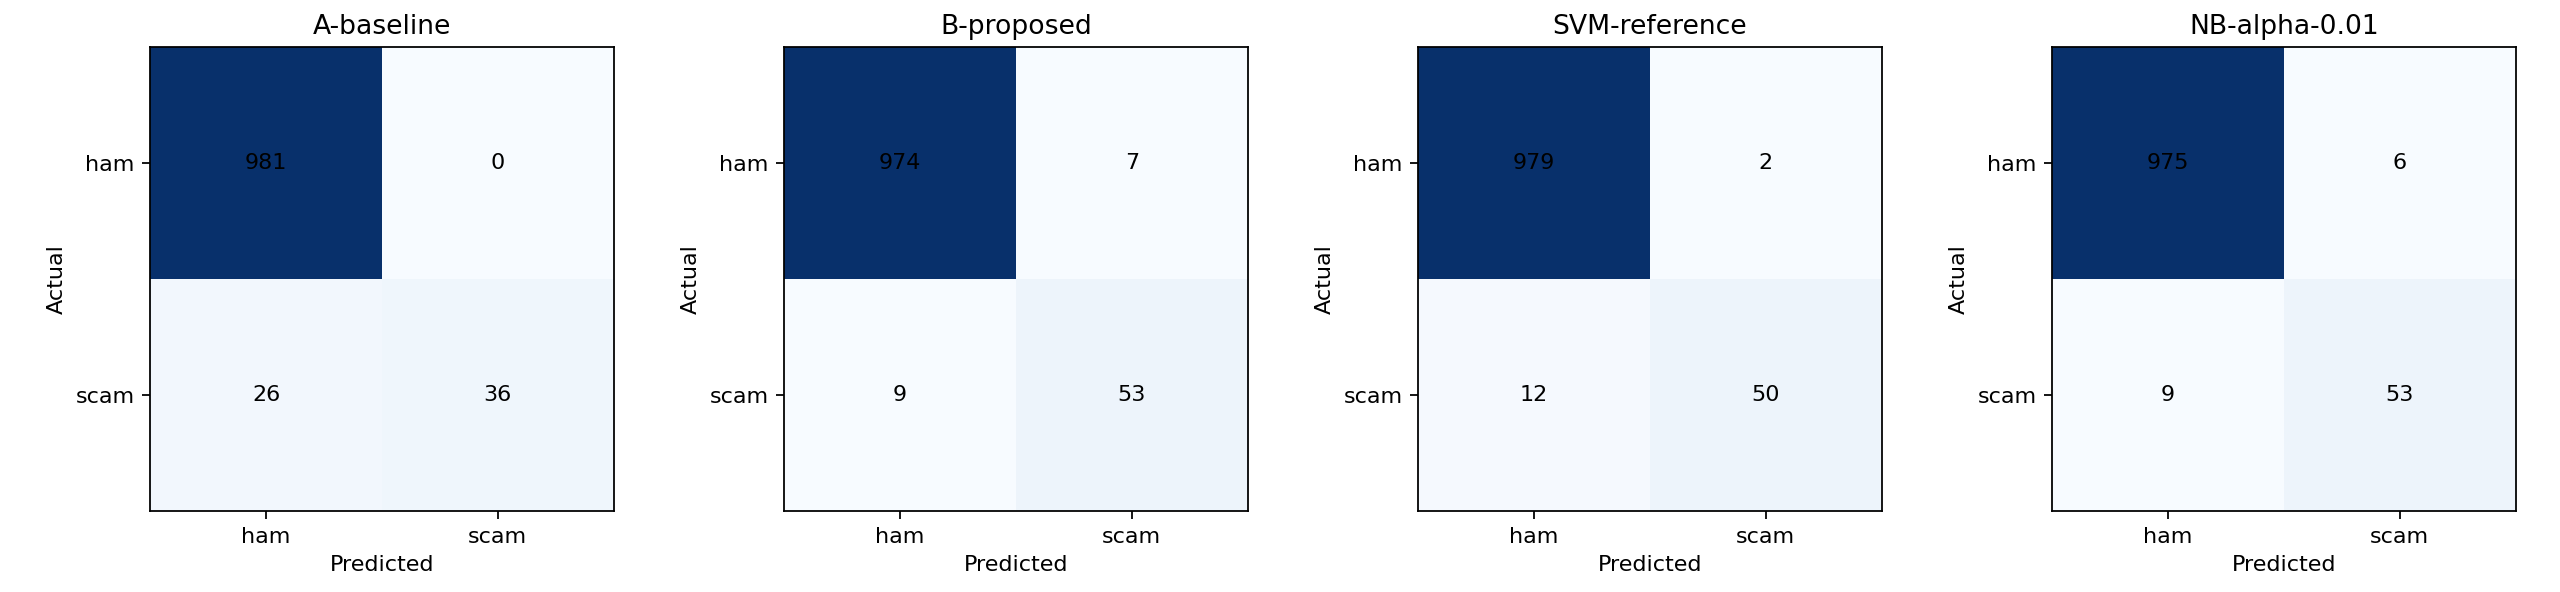

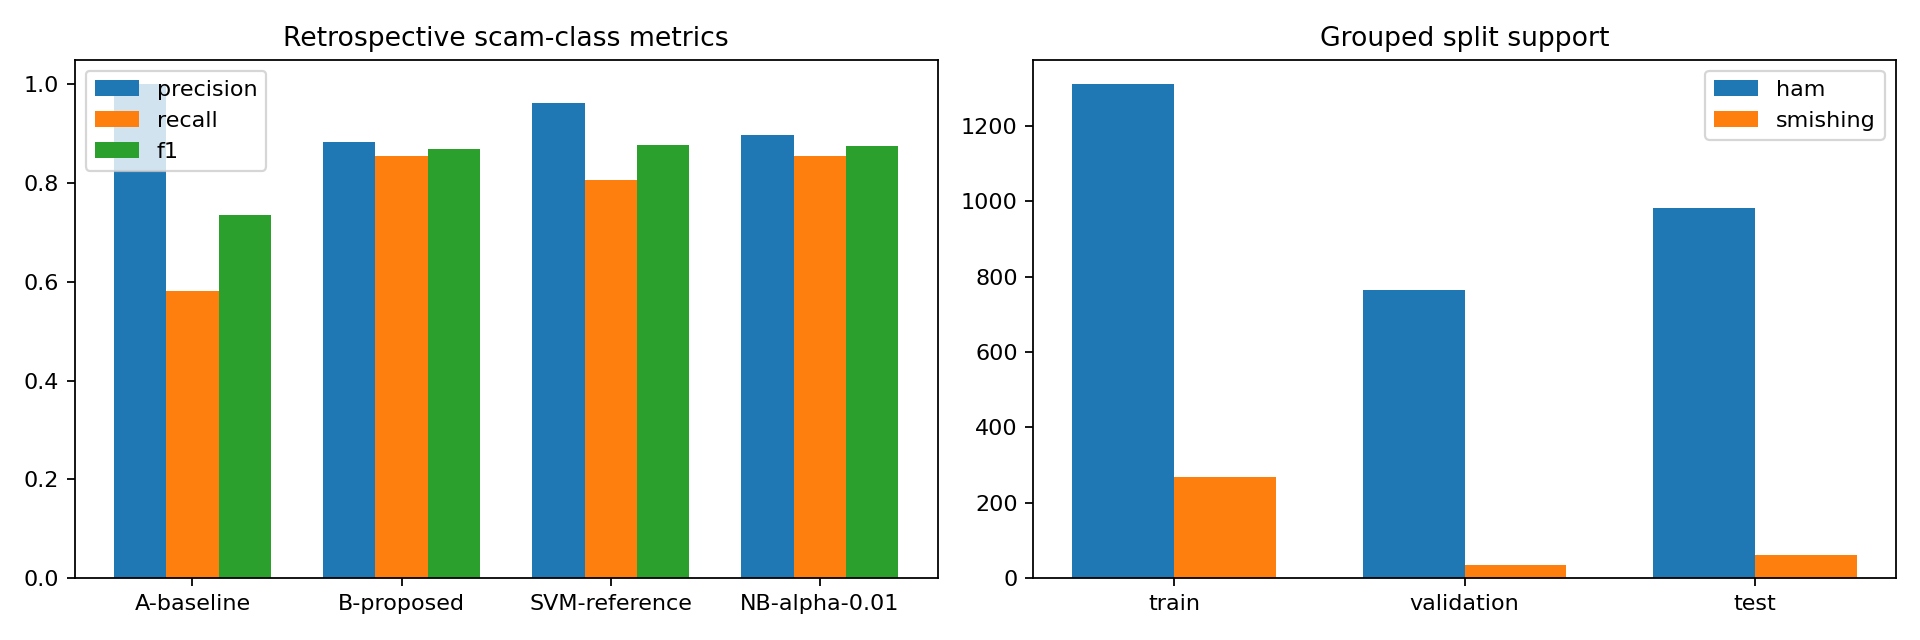

In [4]:
experiment.evaluate(DATASET_PATH, OUTPUT_PATH)
experiment.plots(OUTPUT_PATH)
table = pd.read_csv(OUTPUT_PATH/'comparison.csv')
display(table)
results = experiment.load(OUTPUT_PATH/'test-results.json')
for result in results['results']:
    print(result['spec']['id'], 'class-level report')
    display(pd.DataFrame(result['test']['classification_report']).T)
    print('Language metadata:', result['language'])
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_PATH/'confusion-matrices.png')))
display(Image(filename=str(OUTPUT_PATH/'comparison.png')))


## 5. Offline inference evidence and Android compatibility

Save classifier and vectorizer pickles, exact preprocessing configuration, metadata,
split/cleaning ledgers, validation/test predictions and a separate schema-8 JSON
candidate. JSON reference inference independently reconstructs TF-IDF features and
scores for frozen test messages and synthetic English, Tagalog, Taglish, URL, numeric,
short, random and financial-scam probes. These probes have no measured research labels.
Pickles must only be loaded from this trusted run.

An all-unknown vector returns NB's class prior (or SVM's intercept), which is not
fraud evidence. The diagnostic wrapper abstains for zero-feature input; benchmark
classification metrics above retain the unmodified model decision. Other recognizable
random fragments can still receive high scores. Scores are **uncalibrated**, including
NB posteriors. The diagnostic abstention policy is not a validated production policy.

The Android ModelLoader currently supports different schema/tokenization contracts.
Its scorers split URLs/amounts and use at least two word characters; its masking
adapter also changes these raw inputs. Schema 8 is deliberately separate and marked
android_compatible=false. A matching Kotlin tokenizer/TF-IDF/linear scorer and actual
JVM/device parity are required before deployment. Python JSON parity is not Android
parity. No app model, warning behavior, asset or production pointer is changed.


In [5]:
for result in results['results']:
    name = result['spec']['id']
    checks = experiment.load(OUTPUT_PATH/name/'inference-checks.json')
    print(name, {k:v for k,v in checks.items() if k != 'probes'})
    display(pd.DataFrame(checks['probes'][:15]).drop(columns=['text']))
print('Reproducibility metadata:', experiment.load(OUTPUT_PATH/'metadata.json'))
print('Artifacts saved to:', OUTPUT_PATH)
experiment.verify_freeze(DATASET_PATH, OUTPUT_PATH)
print('Training and selection freeze reverified.')


A-baseline {'cases': 1158, 'synthetic_cases': 115, 'frozen_test_cases': 1043, 'invalid_input_checks': {'none': 'invalid_input', 'nul': 'invalid_input', 'unpaired_surrogate': 'invalid_input', 'overlong': 'invalid_input'}, 'max_feature_error': 1.6653345369377348e-16, 'max_score_error': 9.992007221626409e-15, 'note': 'Python JSON reference parity only; Android scorer cannot load schema 8. Zero features returns class prior/margin, not evidence of safety or fraud.'}


,name,raw_score,recognized_features,diagnostic_status,suspicious
0,empty,0.169309,0,abstain_zero_features,False
1,punctuation,0.169309,0,abstain_zero_features,False
2,random,0.169309,0,abstain_zero_features,False
3,short,0.169309,0,abstain_zero_features,False
4,numeric,0.169309,0,abstain_zero_features,False
5,url_only,0.169309,0,abstain_zero_features,False
6,ordinary_english,0.038312,7,score_is_uncalibrated,False
7,ordinary_tagalog,0.150295,8,score_is_uncalibrated,False
8,ordinary_taglish,0.313137,8,score_is_uncalibrated,False
9,bank_notice,0.001519,14,score_is_uncalibrated,False


B-proposed {'cases': 1158, 'synthetic_cases': 115, 'frozen_test_cases': 1043, 'invalid_input_checks': {'none': 'invalid_input', 'nul': 'invalid_input', 'unpaired_surrogate': 'invalid_input', 'overlong': 'invalid_input'}, 'max_feature_error': 1.6653345369377348e-16, 'max_score_error': 5.995204332975845e-15, 'note': 'Python JSON reference parity only; Android scorer cannot load schema 8. Zero features returns class prior/margin, not evidence of safety or fraud.'}


,name,raw_score,recognized_features,diagnostic_status,suspicious
0,empty,0.169309,0,abstain_zero_features,False
1,punctuation,0.169309,0,abstain_zero_features,False
2,random,0.169309,0,abstain_zero_features,False
3,short,0.169309,0,abstain_zero_features,False
4,numeric,0.169309,0,abstain_zero_features,False
5,url_only,0.169309,0,abstain_zero_features,False
6,ordinary_english,0.041835,7,score_is_uncalibrated,False
7,ordinary_tagalog,0.216733,8,score_is_uncalibrated,False
8,ordinary_taglish,0.897854,8,score_is_uncalibrated,True
9,bank_notice,0.000116,14,score_is_uncalibrated,False


SVM-reference {'cases': 1158, 'synthetic_cases': 115, 'frozen_test_cases': 1043, 'invalid_input_checks': {'none': 'invalid_input', 'nul': 'invalid_input', 'unpaired_surrogate': 'invalid_input', 'overlong': 'invalid_input'}, 'max_feature_error': 1.6653345369377348e-16, 'max_score_error': 6.661338147750939e-16, 'note': 'Python JSON reference parity only; Android scorer cannot load schema 8. Zero features returns class prior/margin, not evidence of safety or fraud.'}


,name,raw_score,recognized_features,diagnostic_status,suspicious
0,empty,-0.514886,0,abstain_zero_features,False
1,punctuation,-0.514886,0,abstain_zero_features,False
2,random,-0.514886,0,abstain_zero_features,False
3,short,-0.514886,0,abstain_zero_features,False
4,numeric,-0.514886,0,abstain_zero_features,False
5,url_only,-0.514886,0,abstain_zero_features,False
6,ordinary_english,-0.307808,7,score_is_uncalibrated,False
7,ordinary_tagalog,-0.389198,8,score_is_uncalibrated,False
8,ordinary_taglish,-0.201124,8,score_is_uncalibrated,False
9,bank_notice,-1.094543,14,score_is_uncalibrated,False


NB-alpha-0.01 {'cases': 1158, 'synthetic_cases': 115, 'frozen_test_cases': 1043, 'invalid_input_checks': {'none': 'invalid_input', 'nul': 'invalid_input', 'unpaired_surrogate': 'invalid_input', 'overlong': 'invalid_input'}, 'max_feature_error': 1.6653345369377348e-16, 'max_score_error': 5.6066262743570405e-15, 'note': 'Python JSON reference parity only; Android scorer cannot load schema 8. Zero features returns class prior/margin, not evidence of safety or fraud.'}


,name,raw_score,recognized_features,diagnostic_status,suspicious
0,empty,0.169309,0,abstain_zero_features,False
1,punctuation,0.169309,0,abstain_zero_features,False
2,random,0.169309,0,abstain_zero_features,False
3,short,0.169309,0,abstain_zero_features,False
4,numeric,0.169309,0,abstain_zero_features,False
5,url_only,0.169309,0,abstain_zero_features,False
6,ordinary_english,0.033654,7,score_is_uncalibrated,False
7,ordinary_tagalog,0.060125,8,score_is_uncalibrated,False
8,ordinary_taglish,0.991591,8,score_is_uncalibrated,True
9,bank_notice,0.000003,14,score_is_uncalibrated,False


Reproducibility metadata: {'python': '3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]', 'unicode': '15.0.0', 'platform': 'Windows-11-10.0.26200-SP0', 'processor': 'Intel64 Family 6 Model 141 Stepping 1, GenuineIntel', 'packages': {'numpy': '2.2.6', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'pandas': '2.3.3', 'matplotlib': '3.10.7', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0'}, 'implementation_sha256': '5b31231810f1b7598bedc00c18cf76ee08ae7949ab761939f3218b145a2c12ac', 'timestamp_utc': '2026-10-15T16:38:18Z'}
Artifacts saved to: C:\Users\Jassim Trinidad\OneDrive\Desktop\smishguard\research\runs\nb-comparison-20261016\notebook-run-v3
Training and selection freeze reverified.


## 6. Interpretation, limits and reproduction

Compare scam precision/recall/F1 and macro-F1, not accuracy alone. FN means a missed
scam; FP interrupts a legitimate message. The prespecified F1 selection rule gives
neither mistake an explicit deployment cost. Do not call alpha=.1 superior unless
both validation and retrospective test evidence support the bounded claim; no
statistical significance is established by a point estimate.

This corpus's rule-derived labels, historical exposure, source imbalance, heuristic
templates, unknown true campaign boundaries, and unverified receipt timestamps limit
generalization. Financial scams are included but no independently adjudicated financial
subset is available. Metadata combines Filipino/Taglish, so separate Tagalog and Taglish
metrics are unavailable. Small subgroup support cannot establish language robustness.
The 500 gambling_ad records are excluded, limiting conclusions for that traffic.
Source-held-out and prospective independent evaluation remain future confirmation.

Local reproduction: install `research/nb-comparison-requirements.txt`, then
`research/.venv/Scripts/python.exe scripts/execute_nb_comparison_notebook.py --output research/runs/nb-comparison-20261016/NEW-RUN`.
In Colab upload this notebook, configure the ZIP/output paths above, and Run all.
All tables come from execution; no expected or fabricated performance is included.

Method references: [TF-IDF](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[MultinomialNB](https://scikit-learn.org/1.6/modules/generated/sklearn.naive_bayes.MultinomialNB.html),
[StratifiedGroupKFold](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
